In [16]:
from dotenv import load_dotenv
from langchain_core.prompts import ChatPromptTemplate
from langchain_community.document_loaders import PyPDFLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_openai import ChatOpenAI,OpenAIEmbeddings
# from langchain_chroma import Chroma
from langchain_community.vectorstores import Chroma
from langchain_core.documents import Document


from langgraph.graph import StateGraph, START, END, MessagesState
from langchain_core.output_parsers import StrOutputParser
load_dotenv()


True

In [10]:
# step 1 :
pdf_loader = PyPDFLoader("./documents/evs_oil_price_shock.pdf")
raw_docs = pdf_loader.load()


# step 2 split documents into chunks
text_splitter = RecursiveCharacterTextSplitter(chunk_size=900, chunk_overlap=100)
chunks = text_splitter.split_documents(raw_docs)

print(len(chunks))


51


In [12]:
# lets intilize our embedding model
embeddings = OpenAIEmbeddings(model="text-embedding-3-small")

# step 3.1 : intilize your storage system 
vectorstore = Chroma(
    collection_name="rag_base",
    embedding_function=embeddings,
)


# step 3.2 : add documents to your storage system. (chunk --> vectors)
vectorstore.add_documents(chunks)




['0d2fdedf-c3ed-4959-a675-d38f24cf24e2',
 'bdce1c06-527f-453e-b6cf-d78c42fff985',
 '5719d5cc-466c-4ec1-b18b-54424938998a',
 'b2f83587-cdb8-4a8a-8279-76c2f20f3831',
 '84b18e5c-0437-4cd6-9774-60b1bb7c1ce8',
 '271a5c08-246b-415b-882d-da0360529667',
 'ceac8337-bd1c-4a43-a9e2-9b6836aa9394',
 '2890c080-6682-49d3-a966-6085a9f5b0cf',
 '4c55b2fa-27ac-49ec-bb24-090a67029489',
 'ff49eebc-c1b4-4e09-bd28-7a11ea42bcaa',
 'b2419893-3cc1-46ae-967e-d9cd35edf1f5',
 '7b98bd99-5c63-4d86-8778-c6cf85d9d0ba',
 '8936e684-3c2e-4859-8a4b-9755ebaecc40',
 '4825af14-39c5-4acc-96a0-1c25f4a2b7e8',
 'c3e07e9b-fa15-4ce0-8591-203bd1b2e763',
 'afb63986-1e40-4f85-9bae-ddd4968e2a91',
 '688d2980-c525-4abf-9ac7-427f9095d132',
 'ef0226dc-5914-4a26-8a1a-ebb1b7e84087',
 'd874bfd1-7107-4afc-9413-39380f3e9313',
 '00c09876-0165-47df-9d27-c8d33645a246',
 'dae243d9-1914-462d-872b-e4c8d61ead01',
 'd4fbe765-69a5-4183-adee-ad5f31f22a67',
 '66ba3473-f9c3-4cfc-ae7a-d9a66957ebd6',
 'acca2d56-e070-42f9-8c28-f368de852eaa',
 'e8324f52-af5f-

In [13]:
# step 4 : retrieval

retriever = vectorstore.as_retriever( search_kwargs={"k": 2})

In [17]:
# step 1 : Define your state
class AgenticRAGState(MessagesState):
    query: str
    retrieved_docs: list[Document]
    context: str
    generation: str


llm = ChatOpenAI(model="gpt-5-mini")


In [18]:
# step 2 : lets define the node
def retrieve(state: AgenticRAGState):
    docs = retriever.invoke(state['query'])
    context = "\n\n".join([doc.page_content for doc in docs])
    return {"retrieved_docs": docs, "context": context} 



def generate(state: AgenticRAGState):
    query = state['query']
    context = state['context']
    prompt_template = ChatPromptTemplate.from_messages([
        ("system", "Answer the question using only the context below.\n\nContext:\n{context}"),
        ("human", query)
    ])
    chain = prompt_template | llm | StrOutputParser()

    response = chain.invoke({"context": context, "query": query})
    return {"generation": response}



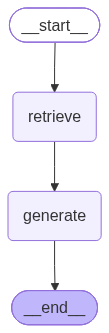

In [19]:
graph_builder = StateGraph(AgenticRAGState)

graph_builder.add_node("retrieve", retrieve)
graph_builder.add_node("generate", generate)

# now we will connect them using edges
graph_builder.add_edge(START, "retrieve")
graph_builder.add_edge("retrieve", "generate")
graph_builder.add_edge("generate", END)

graph = graph_builder.compile()

graph

In [20]:
test_query = "How will EVS impact oil demand in the next decade?"
result = graph.invoke({"query": test_query,"messages": []})

In [21]:
result

{'messages': [],
 'query': 'How will EVS impact oil demand in the next decade?',
 'retrieved_docs': [Document(metadata={'title': '(anonymous)', 'total_pages': 15, 'trapped': '/False', 'author': '(anonymous)', 'moddate': '2026-04-18T21:49:03+05:00', 'page': 3, 'keywords': '', 'creationdate': '2026-04-18T21:49:03+05:00', 'page_label': '4', 'creator': '(unspecified)', 'subject': '(unspecified)', 'source': './documents/evs_oil_price_shock.pdf', 'producer': 'ReportLab PDF Library - (opensource)'}, page_content='Energy Agency, and McKinsey collectively project that EVs will account for between 40 and\n60 percent of new vehicle sales globally by 2030. The stock of EVs on the road — which\nmatters more than annual sales for oil displacement — is projected to grow from roughly 40\nmillion vehicles today to between 300 and 500 million by the early 2030s. Whether this is\nsufficient to materially alter the oil price formation process is the central question this report\naddresses.\n1.1 Scope and 

In [22]:
print(result['generation'])

Short answer
- EVs will reduce oil demand from passenger and light commercial vehicles over the next decade, but they are unlikely to eliminate oil demand or fully reshape global oil markets within that time window.

Why (key facts from the report)
- Adoption pace: Major forecasters collectively project EVs will capture roughly 40–60% of new vehicle sales by 2030.
- Stock growth: The EV fleet is expected to grow from about 40 million today to roughly 300–500 million by the early 2030s — a large increase, and stock (not annual sales) is what displaces oil use.
- Fleet scale and turnover: There are ~1.4 billion passenger vehicles globally and ~90 million new vehicle sales per year. Typical vehicle lifetimes are 15–20 years (often longer in developing markets), so full fleet electrification cannot occur in less than a decade or two.
- Scope limits: This analysis covers passenger and light commercial vehicles only; heavy trucking, aviation, shipping and petrochemical feedstock (together ~4

In [23]:
test_query = "who is PM of india"
result = graph.invoke({"query": test_query,"messages": []})


In [24]:
result

{'messages': [],
 'query': 'who is PM of india',
 'retrieved_docs': [Document(metadata={'subject': '(unspecified)', 'total_pages': 15, 'author': '(anonymous)', 'trapped': '/False', 'producer': 'ReportLab PDF Library - (opensource)', 'moddate': '2026-04-18T21:49:03+05:00', 'title': '(anonymous)', 'source': './documents/evs_oil_price_shock.pdf', 'creationdate': '2026-04-18T21:49:03+05:00', 'page_label': '15', 'keywords': '', 'page': 14, 'creator': '(unspecified)'}, page_content='manage the elevated transition-period vulnerability. The world with 500 million EVs will be\nmeaningfully less exposed to the oil price shocks that have periodically destabilized\neconomies for the past five decades, but it will not be immune to them.'),
  Document(metadata={'producer': 'ReportLab PDF Library - (opensource)', 'creationdate': '2026-04-18T21:49:03+05:00', 'total_pages': 15, 'trapped': '/False', 'creator': '(unspecified)', 'subject': '(unspecified)', 'title': '(anonymous)', 'page_label': '5', 'page'

In [25]:
print(result['generation'])

I can’t determine who the Prime Minister of India is from the provided context — the excerpt discusses EVs, oil-price shocks, and inflation but does not mention any political leaders. Provide additional context or allow outside-source lookup if you want the current name.
